In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import time

<Axes: >

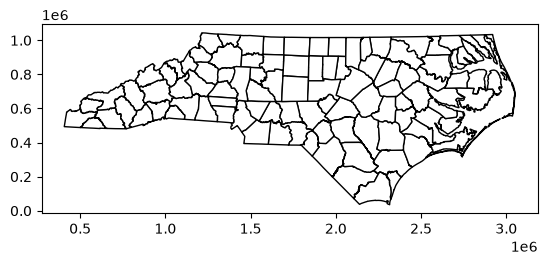

In [2]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

In [3]:
species = ["Pueraria montana"]
year = 2025
api = "https://api.gbif.org/v1"
records = []

for name in species:
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60  
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT"
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "year": year,
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Use a GBIF bulk download."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)

    print(f"{name}: {len(species_records):,} records")

Pueraria montana: 1,618 records


In [4]:
# make the kudzu records into a dataframe
kudzu_df = pd.DataFrame(records)

kudzu_df = kudzu_df[
    [
        "scientificName",
        "decimalLatitude",
        "decimalLongitude",
        "year"
    ]]


kudzu_df.head()

,scientificName,decimalLatitude,decimalLongitude,year
0,Pueraria montana (Lour.) Merr.,30.513145,-86.491081,2025
1,Pueraria montana (Lour.) Merr.,39.804396,-75.151704,2025
2,Pueraria montana (Lour.) Merr.,39.803962,-75.151832,2025
3,Pueraria montana (Lour.) Merr.,39.803338,-75.152185,2025
4,Pueraria montana (Lour.) Merr.,33.841967,-84.438037,2025


In [5]:
kudzu = gpd.GeoDataFrame(
    kudzu_df,
    geometry=gpd.points_from_xy(
        kudzu_df["decimalLongitude"],
        kudzu_df["decimalLatitude"]
    ),
    crs=4326
)

# need to reproject to match NC
kudzu= kudzu.to_crs(6543)

print(len(kudzu))

1618


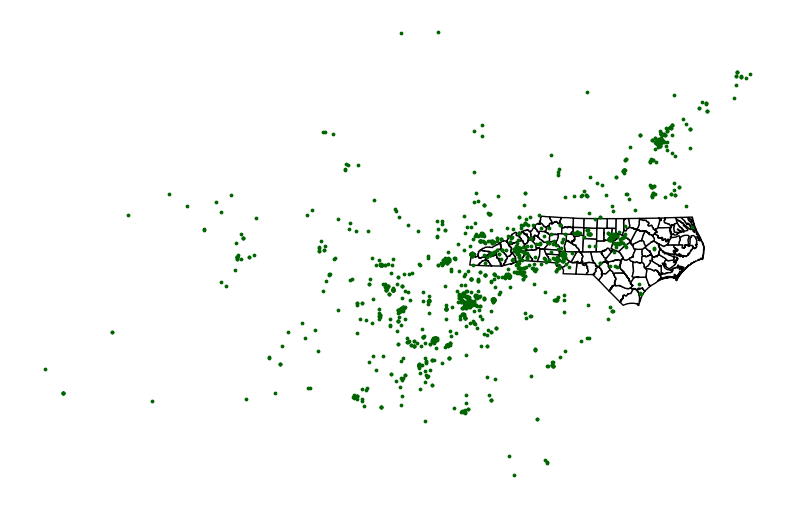

In [6]:
ax = nc_counties.plot(
    edgecolor="black",
    facecolor="white",
    figsize=(10, 10)
)

kudzu.plot(
    ax=ax,
    color="darkgreen",
    markersize=3
)

ax.set_axis_off()
plt.show()

In [7]:
kudzu_join = gpd.sjoin(
    kudzu,
    nc_counties[["NAME", "geometry"]],
    how="inner",
    predicate="within"
)

kudzu_counts = kudzu_join.groupby("NAME").size()

nc_counties["Kudzu_Count"] = (
    nc_counties["NAME"]
    .map(kudzu_counts)
    .fillna(0)
    .astype(int)
)

nc_counties[
    ["NAME", "Kudzu_Count"]
].sort_values(
    "Kudzu_Count",
    ascending=False
).head(10)

,NAME,Kudzu_Count
842,Buncombe,51
2664,Orange,29
1530,Wake,21
700,Mecklenburg,20
1531,Guilford,15
1226,Swain,13
2993,Forsyth,13
1931,Durham,11
219,Henderson,11
3087,Gaston,10


In [8]:
def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#dce8d5"
    )

    selected_kudzu = kudzu_join[
        kudzu_join["NAME"] == county
    ]

    selected_kudzu.plot(
        ax=ax,
        color="green",
        markersize=8,
        alpha=0.7
    )

    ax.set_axis_off()


In [9]:
import inspect
print(inspect.getsource(locator_map))

NameError: name 'locator_map' is not defined

In [ ]:
def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    print("selected rows:", len(selected), "| total counties:", len(nc_counties))
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="crimson", zorder=3)
    ax.set_axis_off()
    print("axis off:", not ax.axison, "| xlim:", ax.get_xlim())

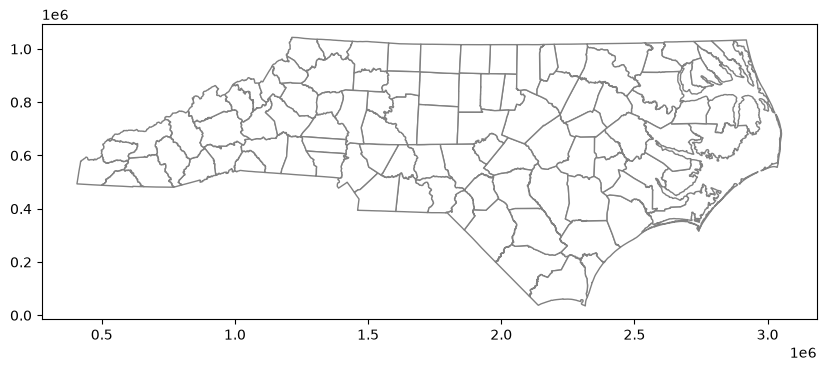

(100, 14) EPSG:6543 [ 406818.48395235   35246.42804916 3052213.66836486 1043617.5564572 ]


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
plt.show()
print(nc_counties.shape, nc_counties.crs, nc_counties.total_bounds)

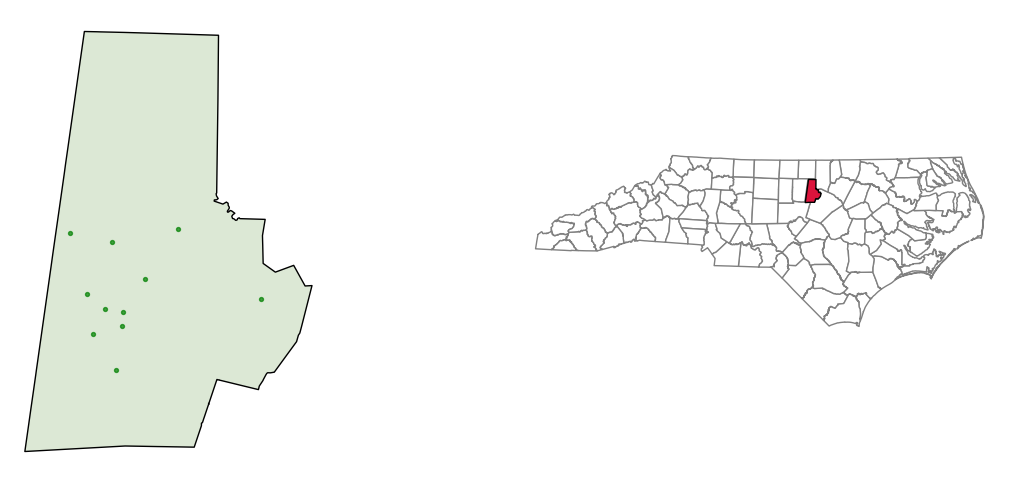

In [ ]:
def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="crimson", zorder=3)
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
county_map("Durham", axes[0])
locator_map("Durham", axes[1])
plt.show()

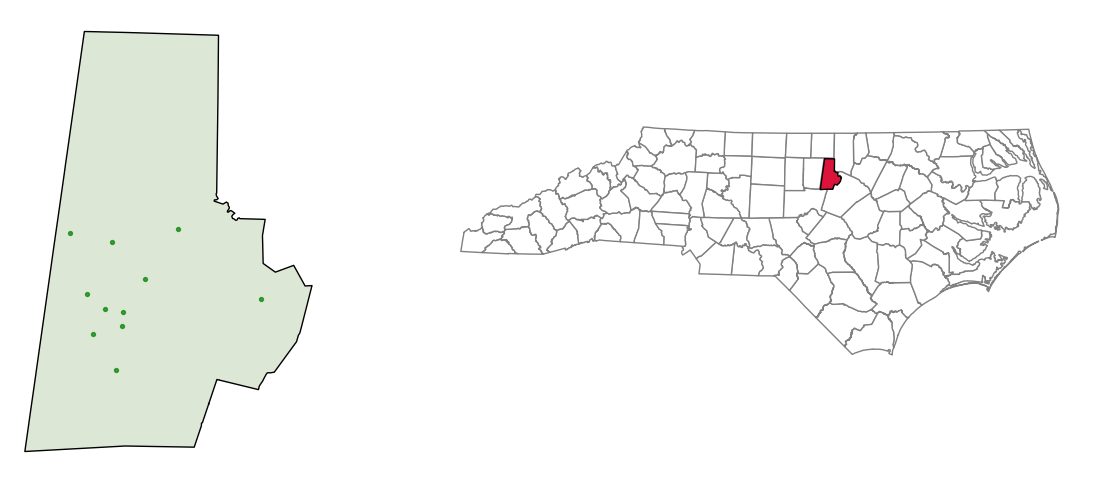

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1, 2]}  # locator map gets more room
)

county_map("Durham", axes[0])
locator_map("Durham", axes[1])


plt.show()

In [ ]:
def county_info(county, ax):

    selected = nc_counties[
        nc_counties["NAME"] == county
    ]

    count = selected["Kudzu_Count"].iloc[0]

    message = (
        "There are " + str(count) +
        " recorded kudzu occurrences in " +
        county + " County."
    )

    ax.text(
        0.05, 0.85,
        "KUDZU OCCURRENCES",
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        color="darkgreen"
    )

    ax.text(
        0.05, 0.55,
        str(count),
        transform=ax.transAxes,
        fontsize=35,
        fontweight="bold",
        color="darkgreen"
    )

    ax.text(
        0.05, 0.25,
        message,
        transform=ax.transAxes,
        fontsize=12,
        wrap=True,
        va="top"
    )

    ax.set_axis_off()

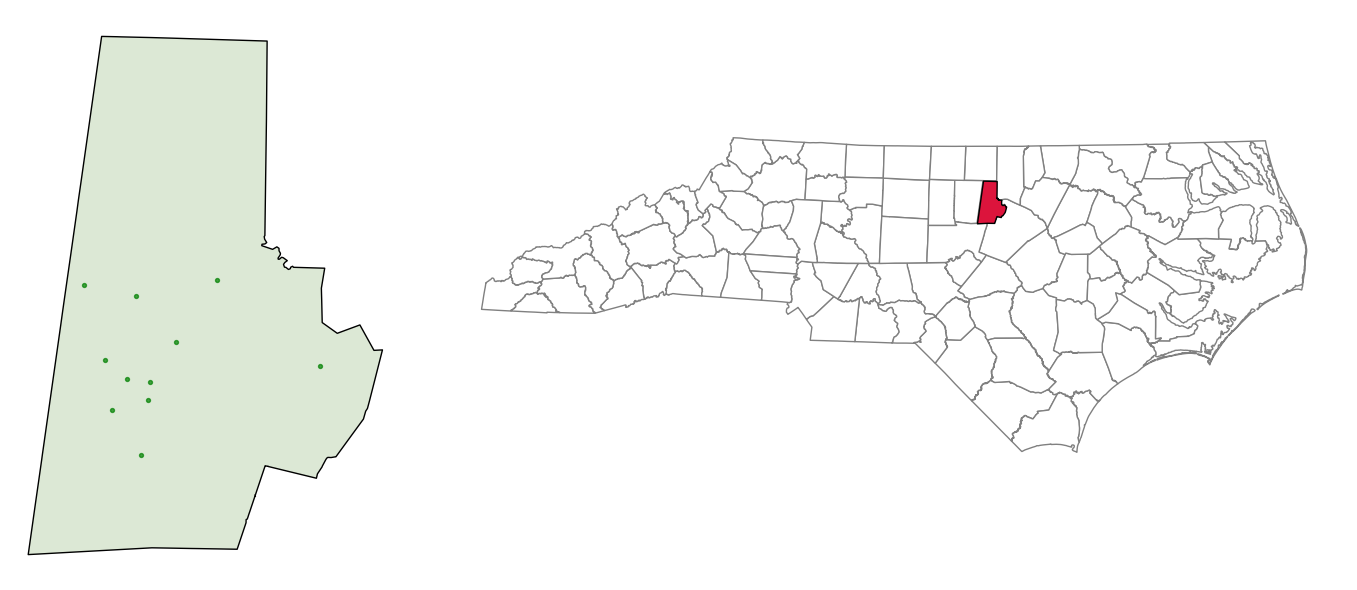

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1, 2]}  # locator map gets more room
)

county_map("Durham", axes[0])
locator_map("Durham", axes[1])

plt.tight_layout()
plt.show()

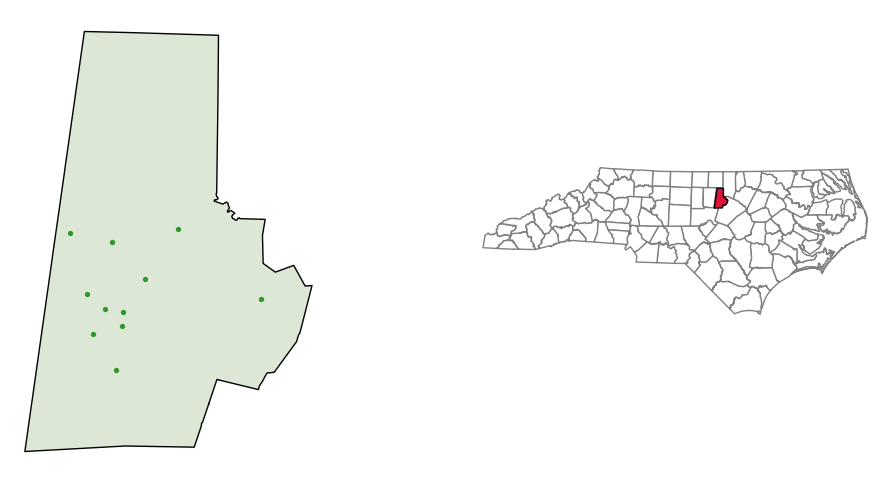

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

county_map("Durham", axes[0])
locator_map("Durham", axes[1])

plt.show()

In [ ]:
county = "Durham"

fig = plt.figure(figsize=(12, 8))

# Create map panels
def county_figure(county, pdf):
    fig = plt.figure(figsize=(12, 8))
    
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
    ax_info = fig.add_axes([0.65, 0.30, 0.30, 0.40])

# Add maps and information
    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)

# Page heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / KUDZU OCCURRENCE ATLAS",
        fontsize=10,
        color="darkgreen"
    )

    fig.text(
        0.05, 0.87,
        county + " County",
        fontsize=28,
        fontweight="bold"
    )

# Footer
    fig.text(
        0.05, 0.03,
        "Source: GBIF occurrence records | U.S. Census Bureau county boundaries",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig, dpi=50)
    plt.close(fig)

<Figure size 1200x800 with 0 Axes>

In [ ]:
# def county_figure(county):
#     fig, axes = plt.subplots(
#         2, 1,
#         figsize=(8, 10),
#         gridspec_kw={"height_ratios": [3, 1]}
#     )

#     county_map(county, axes[0])
#     locator_map(county, axes[1])

#     fig.suptitle(f"{county} County", fontsize=20)

#     fig.savefig(f"{county}_County.pdf")
#     plt.close(fig)

In [ ]:
# county_figure("Mecklenburg")

In [ ]:
# def county_figure(county, pdf):
#     fig, axes = plt.subplots(
#         2, 1,
#         figsize=(8, 10),
#         gridspec_kw={"height_ratios": [3, 1]}
#     )

#     county_map(county, axes[0])
#     locator_map(county, axes[1])

#     fig.suptitle(f"{county} County", fontsize=20)

#     pdf.savefig(fig)
#     plt.close(fig)

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages 

In [ ]:
nc_counties = nc_counties.sort_values(
    "NAME"
).reset_index(drop=True)

with PdfPages("NC_Kudzu_Atlas.pdf") as pdf:
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

/var/folders/kk/72ztnpsd38jbj10y4p5tz8xm0000gn/T/ipykernel_11934/4203604380.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  selected_kudzu.plot(
/var/folders/kk/72ztnpsd38jbj10y4p5tz8xm0000gn/T/ipykernel_11934/4203604380.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  selected_kudzu.plot(
/var/folders/kk/72ztnpsd38jbj10y4p5tz8xm0000gn/T/ipykernel_11934/4203604380.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  selected_kudzu.plot(
/var/folders/kk/72ztnpsd38jbj10y4p5tz8xm0000gn/T/ipykernel_11934/4203604380.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  selected_kudzu.plot(
/var/folders/kk/72ztnpsd38jbj10y4p5tz8xm0000gn/T/ipykernel_11934/4203604380.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  selected_kudzu.p

In [10]:
%pip install nbconvert


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
